# Figures: 2-qubit protocol at the physical level (multi-round, stable manifold, threshold)

**Inputs** (all in `data/two_qubit/physical_level/`)
- `multiple_rounds/depolarizing_error_rates.npz`, `multiple_rounds/stable_axis_error_rates.npz` (from `multiple_rounds/*.ipynb`)
- `one_round/depolarizing_error_rates.npz`, `one_round/stable_axis_error_rates.npz` (from `one_round/*.ipynb`)
- `multiple_rounds/stable_manifold_error_rates.npz` (from `../stable_manifold.ipynb`)

**Cells**
- *Flow Diagram*: streamlines of the [[2,1,1]] Bloch map on the $y=0$ plane with the fixed point $(x^\star,z^\star)$. Exploratory version.
- First plot cell: 2×2 panels (multi-round decay and threshold for depolarizing and stable-axis noise). Its `savefig` to `figures/repetition_code.png` is commented out.
- Second plot cell: a three-panel variant (stable manifold, multi-round, threshold); not saved.
- Third plot cell: four panels (a) flow diagram, (b) stable-manifold decay, (c) multi-round decay for six initial $p$, (d) one-round threshold $p_\star \approx 0.704$. This matches the committed `figures/repetition_code_combined.png`; the `savefig` line is commented out.

The import of `msd.flow_diagrams` is unused here; the flow field is coded inline.

In [75]:
from qiskit import __version__
print(__version__)

2.4.2


# Importing Packages

In [76]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix, SaveStatevector, SetDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from matplotlib.lines import Line2D
import mpmath as mp


import sys
from pathlib import Path

# Make the shared `msd` package importable regardless of the notebook's depth
src_dir = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from msd.flow_diagrams import get_poly_from_code, poly_dicts_to_sympy, get_stabilizer_code

# Graphing Settings

In [77]:
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    "axes.titlesize": 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# Importing Data

In [78]:
data1 = np.load("../../../data/two_qubit/physical_level/multiple_rounds/depolarizing_error_rates.npz")
data2 = np.load("../../../data/two_qubit/physical_level/multiple_rounds/stable_axis_error_rates.npz")

rounds_arr1 = data1["rounds_arr"]
rounds_arr2 = data2["rounds_arr"]

input_error_rate = data1["input_error_prob_list"]
output_error_rate_matrix1 = data1["output_error_rate_matrix"]
output_error_rate_matrix2 = data2["output_error_rate_matrix"]

lambda1 = data1["lambda_value"]
lambda2 = data2["lambda_value"] 

In [79]:
data3 = np.load("../../../data/two_qubit/physical_level/one_round/depolarizing_error_rates.npz")
data4 = np.load("../../../data/two_qubit/physical_level/one_round/stable_axis_error_rates.npz")

depol_input_error_rate = data3["input_error_rate_list"]
depol_output_error_rate = data3["output_error_rate"]
depol_intersection = data3["intersection"]

conv_input_error_rate = data4["input_error_rate_list"]
conv_output_error_rate = data4["output_error_rate"]
conv_intersection = data4["intersection"]

In [80]:
data5 = np.load("../../../data/two_qubit/physical_level/multiple_rounds/stable_manifold_error_rates.npz")

manifold_rounds_arr = data5["rounds_arr"]
manifold_output_error_rate = data5["output_error_rate"]
manifold_success_probabilities = data5["success_probabilities"]

manifold_t = data5["t"]
manifold_x_in = data5["x_in"]
manifold_z_in = data5["z_in"]

# Flow Diagram

Fixed point:
x* = 0.83928675521416113255
z* = 0.54368901269207636157
Fixed-point residual: 1.1102230246251565e-16


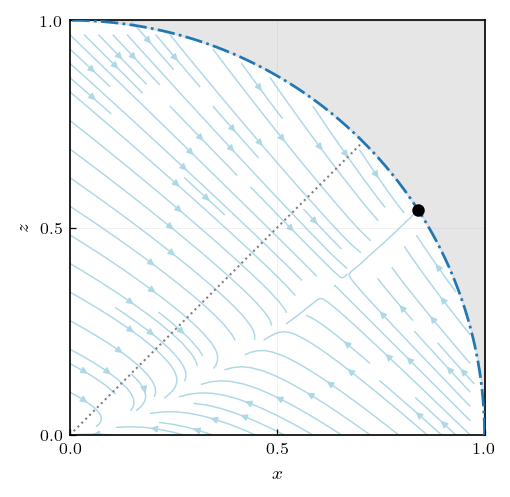

In [74]:
# Bloch map of the accepted branch on y = 0; the nontrivial fixed point
# solves z^3 + z^2 + z = 1 (z_star ~ 0.5437, x_star ~ 0.8393).
# ==========================================================
# 2. [[2,1,1]] dynamical map on y = 0
#
# T(x,z) = (
#     2z / (1+z^2),
#     x^2 / (1+z^2)
# )
# ==========================================================

def Tx(x, z):
    return 2*z / (1 + z**2)


def Tz(x, z):
    return x**2 / (1 + z**2)


def vector_field(x, z):
    return Tx(x, z) - x, Tz(x, z) - z


# ==========================================================
# 3. Calculate the nontrivial fixed point
# ==========================================================

mp.mp.dps = 100

zstar = mp.findroot(
    lambda z: z**3 + z**2 + z - 1,
    (mp.mpf("0.5"), mp.mpf("0.6"))
)

xstar = mp.sqrt(1 - zstar**2)

xf = float(xstar)
zf = float(zstar)

print("Fixed point:")
print("x* =", mp.nstr(xstar, 20))
print("z* =", mp.nstr(zstar, 20))

# Verify fixed-point condition
fixed_residual = np.hypot(
    Tx(xf, zf) - xf,
    Tz(xf, zf) - zf
)

print("Fixed-point residual:", fixed_residual)

assert fixed_residual < 1e-12


# ==========================================================
# 4. Plot flow diagram
# ==========================================================

fig, ax = plt.subplots(
    figsize=(3.4, 3.2),
    constrained_layout=True
)

# ----------------------------------------------------------
# Flow field
# ----------------------------------------------------------

grid_size = 60

xs_grid = np.linspace(0, 1, grid_size)
zs_grid = np.linspace(0, 1, grid_size)

X, Z = np.meshgrid(xs_grid, zs_grid)

U, V = vector_field(X, Z)

# Restrict streamlines to physical Bloch disk
inside = X**2 + Z**2 <= 1

U = np.where(inside, U, np.nan)
V = np.where(inside, V, np.nan)

ax.streamplot(
    xs_grid,
    zs_grid,
    U,
    V,
    density=1.0,
    color="lightblue",
    linewidth=0.7,
    arrowsize=0.65,
    broken_streamlines=True,
    zorder=1
)

# ----------------------------------------------------------
# Nonphysical region
# ----------------------------------------------------------

x_fill = np.linspace(0, 1, 500)

ax.fill_between(
    x_fill,
    np.sqrt(1 - x_fill**2),
    1,
    color="lightgrey",
    alpha=0.55,
    zorder=0
)

# ----------------------------------------------------------
# Bloch disk boundary
# ----------------------------------------------------------

theta = np.linspace(0, np.pi/2, 500)

ax.plot(
    np.cos(theta),
    np.sin(theta),
    linestyle="-.",
    color="C0",
    linewidth=1.3,
    label="Bloch boundary",
    zorder=3
)

# ----------------------------------------------------------
# x = z reference line
# ----------------------------------------------------------

diag = np.linspace(0, 1/np.sqrt(2), 300)

ax.plot(
    diag,
    diag,
    linestyle=":",
    color="gray",
    linewidth=1.0,
    zorder=2
)

# ----------------------------------------------------------
# Fixed point
# ----------------------------------------------------------

ax.scatter(
    xf,
    zf,
    color="black",
    s=25,
    zorder=10
)


# ----------------------------------------------------------
# Axes
# ----------------------------------------------------------

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$z$")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_aspect("equal", adjustable="box")

ax.set_xticks([0, 0.5, 1])
ax.set_yticks([0, 0.5, 1])

ax.tick_params(
    direction="in",
    width=0.6,
    length=3
)

ax.grid(
    alpha=0.2,
    linewidth=0.4
)


plt.show()


# Plots

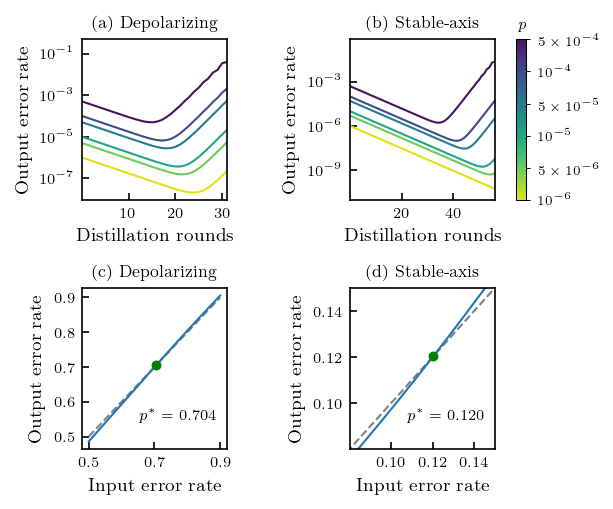

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm, Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

p_values = np.asarray(input_error_rate, dtype=float)
p_sorted = np.sort(np.unique(p_values))
n_colors = len(p_sorted)

# Smooth gradient using the same color range as before.
p_cmap = LinearSegmentedColormap.from_list(
    "p_gradient",
    plt.cm.viridis_r(np.linspace(0.05, 0.95, 256)),
    N=256,
)

p_norm = Normalize(vmin=0, vmax=n_colors - 1)

# Match each curve to its position on the color bar.
colors = p_cmap(p_norm(np.searchsorted(p_sorted, p_values)))



fig, axes = plt.subplots(
    2, 2,
    figsize=(5.5, 3),
    sharex=False,
    sharey=False,
)




# Consistent formatting for all four panels.
for ax in axes.flat:
    ax.tick_params(
        which="both",
        direction="in",
        top=False,
        right=False,
        labelsize=7,
    )
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())


# ==========================================================
# (a) Depolarizing noise: multiple distillation rounds
# ==========================================================

ax = axes[0, 0]

for curve, color in zip(output_error_rate_matrix1, colors):
    ax.plot(
        rounds_arr1,
        curve,
        color=color,
        linewidth=1.0,
    )

ax.set_xlim(0, 31)
ax.set_yscale("log")
ax.set_xlabel("Distillation rounds")
ax.set_ylabel("Output error rate")
ax.set_title("(a) Depolarizing", loc="center", fontsize=8)

ax.set_xticks([10, 20, 30])
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_minor_locator(mticker.NullLocator())


# ==========================================================
# (b) Stable-axis noise: multiple distillation rounds
# ==========================================================

ax = axes[0, 1]

for curve, color in zip(output_error_rate_matrix2, colors):
    ax.plot(
        rounds_arr2,
        curve,
        color=color,
        linewidth=1.0,
    )

ax.set_xlim(0, 56)
ax.set_yscale("log")
ax.set_xlabel("Distillation rounds")
ax.set_ylabel("Output error rate")
ax.set_title("(b) Stable-axis", loc="center", fontsize=8)

ax.set_xticks([20, 40])
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_minor_locator(mticker.NullLocator())


# ==========================================================
# Color bar beside panel (b)
# ==========================================================

def scientific_label(value):
    exponent = int(np.floor(np.log10(value)))
    coefficient = value / 10.0**exponent

    if np.isclose(coefficient, 1):
        return rf"$10^{{{exponent}}}$"

    return rf"${coefficient:g}\times10^{{{exponent}}}$"


cax = axes[0, 1].inset_axes([1.15, 0.0, 0.07, 1.0])

cbar = fig.colorbar(
    ScalarMappable(norm=p_norm, cmap=p_cmap),
    cax=cax,
    ticks=np.arange(n_colors),
)

cbar.ax.set_yticklabels([
    scientific_label(p) for p in p_sorted
])
cbar.ax.set_title(r"$p$", fontsize=7, pad=5)
cbar.ax.tick_params(labelsize=6, length=2, width=0.5)
cbar.ax.minorticks_off()
cbar.outline.set_linewidth(0.5)


# ==========================================================
# (c) Depolarizing noise: input vs. output error rate
# ==========================================================

ax = axes[1, 0]

ax.plot(
    depol_input_error_rate,
    depol_input_error_rate,
    color="gray",
    linestyle="--",
    linewidth=1.0,
)

ax.plot(
    depol_input_error_rate,
    depol_output_error_rate,
    linewidth=1.0,
)

ax.scatter(
    depol_intersection,
    depol_intersection,
    color="green",
    s=14,
    zorder=5,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Input error rate")
ax.set_ylabel("Output error rate")
ax.set_title("(c) Depolarizing", loc="center", fontsize=8)

ax.set_xscale("linear")
ax.set_yscale("linear")

ax.set_xticks([0.5, 0.7, 0.9])
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9])

ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))

ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_minor_locator(mticker.NullLocator())


# ==========================================================
# (d) Stable-axis noise: input vs. output error rate
# ==========================================================

ax = axes[1, 1]

ax.plot(
    conv_input_error_rate,
    conv_input_error_rate,
    color="gray",
    linestyle="--",
    linewidth=1.0,
)

ax.plot(
    conv_input_error_rate,
    conv_output_error_rate,
    linewidth=1.0,
)

ax.scatter(
    conv_intersection,
    conv_intersection,
    color="green",
    s=14,
    zorder=5,
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Input error rate")
ax.set_ylabel("Output error rate")
ax.set_title("(d) Stable-axis", loc="center", fontsize=8)

ax.set_xscale("linear")
ax.set_yscale("linear")

ax.set_xticks([0.1, 0.12, 0.14])
ax.set_yticks([0.1, 0.12, 0.14])

ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))

ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_minor_locator(mticker.NullLocator())

ax.set_xlim(0.08, 0.15)
ax.set_ylim(0.08, 0.15)


# Panel (c): below the panel label, above the curve.
axes[1, 0].text(
    0.92, 0.25,
    rf"$p^*={float(depol_intersection):.3f}$",
    transform=axes[1, 0].transAxes,
    fontsize=7,
    ha="right",
    va="top",
)

# Panel (d): below the curve, toward the right.
axes[1, 1].text(
    0.92, 0.25,
    rf"$p^*={float(conv_intersection):.3f}$",
    transform=axes[1, 1].transAxes,
    fontsize=7,
    ha="right",
    va="top",
)


# ==========================================================
# Figure spacing
# ==========================================================

fig.subplots_adjust(
    left=0.17,
    right=0.67,
    bottom=0.03, 
    top=0.94,
    wspace=0.85,
    hspace=0.55,
)

# fig.savefig("../../../figures/repetition_code.png", dpi=300, bbox_inches="tight")

plt.show()

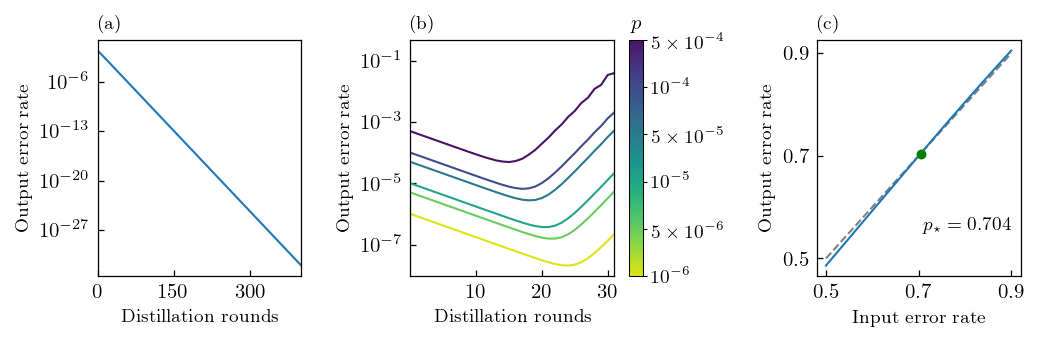

In [67]:
p_values = np.asarray(input_error_rate, dtype=float)
p_sorted = np.sort(np.unique(p_values))
n_colors = len(p_sorted)

p_cmap = LinearSegmentedColormap.from_list(
    "p_gradient",
    plt.cm.viridis_r(np.linspace(0.05, 0.95, 256)),
    N=256,
)

p_norm = Normalize(
    vmin=0,
    vmax=max(n_colors - 1, 1),
)

colors = p_cmap(
    p_norm(np.searchsorted(p_sorted, p_values))
)


# ==========================================================
# Layout: narrower panels with extra space before panel (c)
#
# Columns: (a), (b), colorbar, spacer, (c)
# ==========================================================

fig = plt.figure(
    figsize=(6.8, 2.15),
    layout="constrained",
)

gs = fig.add_gridspec(
    nrows=1,
    ncols=6,
    width_ratios=[1, 0.12, 1, 0.07, 0.12, 1],
)

ax_a = fig.add_subplot(gs[0, 0])
# Column 1: spacer
ax_b = fig.add_subplot(gs[0, 2])
cax = fig.add_subplot(gs[0, 3])
# Column 4: spacer
ax_c = fig.add_subplot(gs[0, 5])

axes = [ax_a, ax_b, ax_c]

fig.set_constrained_layout_pads(
    w_pad=0.035,
    h_pad=0.035,
    wspace=0.04,
    hspace=0.02,
)


# ==========================================================
# Consistent axis formatting
# ==========================================================

for ax in axes:
    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=False,
        right=False,
        labelsize=10,
        width=0.6,
        length=3,
    )

    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)

    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)


# ==========================================================
# (a) Stable-manifold error rate
# ==========================================================

ax_a.plot(
    manifold_rounds_arr,
    manifold_output_error_rate,
    color="tab:blue",
    linewidth=1.0,
)

ax_a.set_yscale("log")

ax_a.set_xlabel("Distillation rounds", fontsize=9)
ax_a.set_ylabel("Output error rate", fontsize=9)
ax_a.set_title("(a)", loc="left", fontsize=9, pad=5)

ax_a.set_xlim(
    np.min(manifold_rounds_arr),
    np.max(manifold_rounds_arr),
)

ax_a.xaxis.set_major_locator(
    mticker.MaxNLocator(nbins=3, integer=True)
)

ax_a.yaxis.set_major_locator(
    mticker.LogLocator(base=10, numticks=5)
)
ax_a.yaxis.set_major_formatter(
    mticker.LogFormatterMathtext(base=10)
)

ax_a.xaxis.set_minor_locator(mticker.NullLocator())
ax_a.yaxis.set_minor_locator(mticker.NullLocator())


# ==========================================================
# (b) Multiple distillation rounds
# ==========================================================

for curve, color in zip(output_error_rate_matrix1, colors):
    ax_b.plot(
        rounds_arr1,
        curve,
        color=color,
        linewidth=1.0,
    )

ax_b.set_xlim(0, 31)
ax_b.set_yscale("log")

ax_b.set_xlabel("Distillation rounds", fontsize=9)
ax_b.set_ylabel("Output error rate", fontsize=9)
ax_b.set_title("(b)", loc="left", fontsize=9, pad=5)

ax_b.set_xticks([10, 20, 30])

ax_b.yaxis.set_major_locator(
    mticker.LogLocator(base=10, numticks=5)
)
ax_b.yaxis.set_major_formatter(
    mticker.LogFormatterMathtext(base=10)
)

ax_b.xaxis.set_minor_locator(mticker.NullLocator())
ax_b.yaxis.set_minor_locator(mticker.NullLocator())


# ==========================================================
# Colorbar for panel (b)
# ==========================================================

def scientific_label(value):
    if value == 0:
        return r"$0$"

    exponent = int(np.floor(np.log10(value)))
    coefficient = value / 10.0**exponent

    if np.isclose(coefficient, 1):
        return rf"$10^{{{exponent}}}$"

    return rf"${coefficient:g}\times10^{{{exponent}}}$"


cbar = fig.colorbar(
    ScalarMappable(norm=p_norm, cmap=p_cmap),
    cax=cax,
    ticks=np.arange(n_colors),
)

cbar.ax.set_yticklabels([
    scientific_label(p) for p in p_sorted
])

cbar.ax.set_title(r"$p$", fontsize=10, pad=5)

cbar.ax.tick_params(
    labelsize=9,
    length=2,
    width=0.5,
    pad=2,
)

cbar.ax.minorticks_off()
cbar.outline.set_linewidth(0.5)


# ==========================================================
# (c) Input vs. output error rate
# ==========================================================

# Identity line
ax_c.plot(
    depol_input_error_rate,
    depol_input_error_rate,
    color="gray",
    linestyle="--",
    linewidth=1.0,
)

# Distillation output
ax_c.plot(
    depol_input_error_rate,
    depol_output_error_rate,
    color="tab:blue",
    linewidth=1.0,
)

# Threshold intersection
ax_c.scatter(
    depol_intersection,
    depol_intersection,
    color="green",
    s=14,
    zorder=5,
)

ax_c.set_xlabel("Input error rate", fontsize=9)
ax_c.set_ylabel("Output error rate", fontsize=9)
ax_c.set_title("(c)", loc="left", fontsize=9, pad=5)

ax_c.set_xticks([0.5, 0.7, 0.9])
ax_c.set_yticks([0.5, 0.7, 0.9])

ax_c.xaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.1f")
)
ax_c.yaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.1f")
)

ax_c.xaxis.set_minor_locator(mticker.NullLocator())
ax_c.yaxis.set_minor_locator(mticker.NullLocator())

ax_c.text(
    0.95,
    0.25,
    rf"$p_\star={float(depol_intersection):.3f}$",
    transform=ax_c.transAxes,
    fontsize=9,
    ha="right",
    va="top",
)

#fig.savefig("../../../figures/repetition_code_combined.png", dpi=300, bbox_inches="tight")

plt.show()

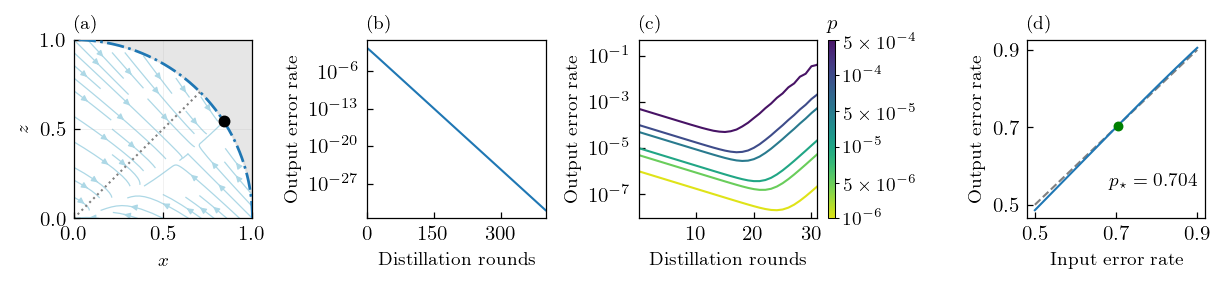

In [ ]:
# Layout of figures/repetition_code_combined.png (savefig commented out below).
# ==========================================================
# 2. [[2,1,1]] dynamical map and fixed point
# ==========================================================

def Tx(x, z):
    return 2*z / (1 + z**2)

def Tz(x, z):
    return x**2 / (1 + z**2)

def vector_field(x, z):
    return Tx(x, z) - x, Tz(x, z) - z

mp.mp.dps = 100

zstar = mp.findroot(
    lambda z: z**3 + z**2 + z - 1,
    (mp.mpf("0.5"), mp.mpf("0.6"))
)

xstar = mp.sqrt(1 - zstar**2)

xf = float(xstar)
zf = float(zstar)

fixed_residual = np.hypot(
    Tx(xf, zf) - xf,
    Tz(xf, zf) - zf
)

assert fixed_residual < 1e-12

# ==========================================================
# 3. Colormap for panel (c)
# ==========================================================

p_values = np.asarray(input_error_rate, dtype=float)
p_sorted = np.sort(np.unique(p_values))
n_colors = len(p_sorted)

p_cmap = LinearSegmentedColormap.from_list(
    "p_gradient",
    plt.cm.viridis_r(np.linspace(0.05, 0.95, 256)),
    N=256,
)

p_norm = Normalize(
    vmin=0,
    vmax=max(n_colors - 1, 1),
)

colors = p_cmap(
    p_norm(np.searchsorted(p_sorted, p_values))
)

# ==========================================================
# 4. Four-panel layout
#
# (a) Flow diagram
# (b) Stable-manifold error rate
# (c) Multiple distillation rounds
# (d) Input vs. output error rate
#
# Colorbar is inset relative to panel (c).
# ==========================================================

fig = plt.figure(
    figsize=(8.0, 2.8),
    layout="constrained",
)

gs = fig.add_gridspec(
    nrows=1,
    ncols=7,
    width_ratios=[
        1, 0.08,    # (a), spacer
        1, 0.08,    # (b), spacer
        1, 0.27,    # (c), colorbar space
        1           # (d)
    ],
)

ax_flow = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 2])
ax_c = fig.add_subplot(gs[0, 4])
ax_d = fig.add_subplot(gs[0, 6])

axes = [ax_flow, ax_b, ax_c, ax_d]

fig.set_constrained_layout_pads(
    w_pad=0.015,
    h_pad=0.015,
    wspace=0.015,
    hspace=0.015,
)

# Make all four plotting areas square
for ax in axes:
    ax.set_box_aspect(1)

# Colorbar: same height as panel (c)
cax = ax_c.inset_axes([
    1.06,   # Closer to panel (c)
    0.0,    # Bottom aligned
    0.04,   # Colorbar width
    1.0,    # Exactly the same height as panel (c)
])

# ==========================================================
# 5. Consistent axis formatting
# ==========================================================

for ax in axes:
    ax.tick_params(
        axis="both",
        which="both",
        direction="in",
        top=False,
        right=False,
        labelsize=10,
        width=0.6,
        length=3,
    )

    ax.xaxis.label.set_size(8)
    ax.yaxis.label.set_size(8)

    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)

# ==========================================================
# (a) Flow diagram
# ==========================================================

grid_size = 60

xs_grid = np.linspace(0, 1, grid_size)
zs_grid = np.linspace(0, 1, grid_size)

X, Z = np.meshgrid(xs_grid, zs_grid)

U, V = vector_field(X, Z)

inside = X**2 + Z**2 <= 1

U = np.where(inside, U, np.nan)
V = np.where(inside, V, np.nan)

# Nonphysical region
x_fill = np.linspace(0, 1, 500)

ax_flow.fill_between(
    x_fill,
    np.sqrt(1 - x_fill**2),
    1,
    color="lightgrey",
    alpha=0.55,
    zorder=0,
)

# Flow field: reduced streamline density
ax_flow.streamplot(
    xs_grid,
    zs_grid,
    U,
    V,
    density=0.5,
    color="lightblue",
    linewidth=0.6,
    arrowsize=0.6,
    broken_streamlines=True,
    zorder=1,
)

# Bloch disk boundary
theta = np.linspace(0, np.pi/2, 500)

ax_flow.plot(
    np.cos(theta),
    np.sin(theta),
    linestyle="-.",
    color="C0",
    linewidth=1.3,
    zorder=3,
)

# x = z reference line
diag = np.linspace(0, 1/np.sqrt(2), 300)

ax_flow.plot(
    diag,
    diag,
    linestyle=":",
    color="gray",
    linewidth=1.0,
    zorder=2,
)

# Fixed point
ax_flow.scatter(
    xf,
    zf,
    color="black",
    s=22,
    zorder=10,
)

ax_flow.set_xlabel(r"$x$", fontsize=9)
ax_flow.set_ylabel(r"$z$", fontsize=9)

ax_flow.set_xlim(0, 1)
ax_flow.set_ylim(0, 1)

ax_flow.set_xticks([0, 0.5, 1])
ax_flow.set_yticks([0, 0.5, 1])

ax_flow.grid(alpha=0.2, linewidth=0.4)
ax_flow.set_title("(a)", loc="left", fontsize=9, pad=5)

# ==========================================================
# (b) Stable-manifold error rate
# Original formatting preserved
# ==========================================================

ax_b.plot(
    manifold_rounds_arr,
    manifold_output_error_rate,
    color="tab:blue",
    linewidth=1.0,
)

ax_b.set_yscale("log")

ax_b.set_xlabel("Distillation rounds", fontsize=9)
ax_b.set_ylabel("Output error rate", fontsize=9)
ax_b.set_title("(b)", loc="left", fontsize=9, pad=5)

ax_b.set_xlim(
    np.min(manifold_rounds_arr),
    np.max(manifold_rounds_arr),
)

ax_b.xaxis.set_major_locator(
    mticker.MaxNLocator(nbins=3, integer=True)
)

ax_b.yaxis.set_major_locator(
    mticker.LogLocator(base=10, numticks=5)
)
ax_b.yaxis.set_major_formatter(
    mticker.LogFormatterMathtext(base=10)
)

ax_b.xaxis.set_minor_locator(mticker.NullLocator())
ax_b.yaxis.set_minor_locator(mticker.NullLocator())

# ==========================================================
# (c) Multiple distillation rounds
# Original formatting preserved
# ==========================================================

for curve, color in zip(output_error_rate_matrix1, colors):
    ax_c.plot(
        rounds_arr1,
        curve,
        color=color,
        linewidth=1.0,
    )

ax_c.set_xlim(0, 31)
ax_c.set_yscale("log")

ax_c.set_xlabel("Distillation rounds", fontsize=9)
ax_c.set_ylabel("Output error rate", fontsize=9)
ax_c.set_title("(c)", loc="left", fontsize=9, pad=5)

ax_c.set_xticks([10, 20, 30])

ax_c.yaxis.set_major_locator(
    mticker.LogLocator(base=10, numticks=5)
)
ax_c.yaxis.set_major_formatter(
    mticker.LogFormatterMathtext(base=10)
)

ax_c.xaxis.set_minor_locator(mticker.NullLocator())
ax_c.yaxis.set_minor_locator(mticker.NullLocator())

# ==========================================================
# Colorbar for panel (c)
# Same height as panel (c)
# ==========================================================

def scientific_label(value):
    if value == 0:
        return r"$0$"

    exponent = int(np.floor(np.log10(value)))
    coefficient = value / 10.0**exponent

    if np.isclose(coefficient, 1):
        return rf"$10^{{{exponent}}}$"

    return rf"${coefficient:g}\times10^{{{exponent}}}$"


cbar = fig.colorbar(
    ScalarMappable(norm=p_norm, cmap=p_cmap),
    cax=cax,
    ticks=np.arange(n_colors),
)

cbar.ax.set_yticklabels([
    scientific_label(p) for p in p_sorted
])

cbar.ax.set_title(r"$p$", fontsize=10, pad=5)

cbar.ax.tick_params(
    labelsize=9,
    length=2,
    width=0.5,
    pad=2,
)

cbar.ax.minorticks_off()
cbar.outline.set_linewidth(0.5)

# ==========================================================
# (d) Input vs. output error rate
# Original formatting preserved
# ==========================================================

# Identity line
ax_d.plot(
    depol_input_error_rate,
    depol_input_error_rate,
    color="gray",
    linestyle="--",
    linewidth=1.0,
)

# Distillation output
ax_d.plot(
    depol_input_error_rate,
    depol_output_error_rate,
    color="tab:blue",
    linewidth=1.0,
)

# Threshold intersection
ax_d.scatter(
    depol_intersection,
    depol_intersection,
    color="green",
    s=14,
    zorder=5,
)

ax_d.set_xlabel("Input error rate", fontsize=9)
ax_d.set_ylabel("Output error rate", fontsize=9)
ax_d.set_title("(d)", loc="left", fontsize=9, pad=5)

ax_d.set_xticks([0.5, 0.7, 0.9])
ax_d.set_yticks([0.5, 0.7, 0.9])

ax_d.xaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.1f")
)
ax_d.yaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.1f")
)

ax_d.xaxis.set_minor_locator(mticker.NullLocator())
ax_d.yaxis.set_minor_locator(mticker.NullLocator())

ax_d.text(
    0.95,
    0.25,
    rf"$p_\star={float(depol_intersection):.3f}$",
    transform=ax_d.transAxes,
    fontsize=9,
    ha="right",
    va="top",
)

#fig.savefig("../../../figures/repetition_code_combined.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
#fig.savefig("../../../figures/repetition_code_combined.png", dpi=300, bbox_inches="tight")